In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Анализ данных: Прогнозирование времени доставки еды

**Кейс:** Food Delivery Orders & ETA Logistics Dataset (Kaggle)

**Задача:** спрогнозировать точное количество минут до завершения доставки с момента размещения заказа на основе времени приготовления блюд, дистанции, категории пробок, погоды и характеристик курьера.

**Целевой признак (таргет):** `actual_delivery_time_minutes`

## Шаг 1: Загрузка и первичный осмотр данных
Загружаем датасет и изучаем его структуру: размерность, типы признаков, наличие пропусков.


In [95]:
df = pd.read_csv('/content/drive/MyDrive/Project_urfu/food_delivery_orders_dataset.csv', sep=',')

In [96]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [97]:
df

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,ORD_049996,CUS_00280,RES_0130,DRV_0112,2025-10-25 12:16:00,2025-10-25,12,Saturday,1,City_B,...,Medium,34,5.0,11,19,21.0,0.0,Completed,NaN,4.4
49996,ORD_049997,CUS_00893,RES_0028,DRV_0036,2025-10-05 19:48:00,2025-10-05,19,Sunday,1,City_B,...,High,49,5.0,9,28,29.0,0.0,Completed,NaN,4.8
49997,ORD_049998,CUS_01618,RES_0001,DRV_0071,2025-10-08 12:18:00,2025-10-08,12,Wednesday,0,City_A,...,High,54,4.1,11,18,16.0,0.0,Completed,NaN,4.7
49998,ORD_049999,CUS_00025,RES_0057,DRV_0103,2025-10-20 17:39:00,2025-10-20,17,Monday,0,City_A,...,High,33,4.0,20,17,27.0,1.0,Completed,NaN,3.8


In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  object 
 1   customer_id                          50000 non-null  object 
 2   restaurant_id                        50000 non-null  object 
 3   driver_id                            50000 non-null  object 
 4   order_timestamp                      50000 non-null  object 
 5   order_date                           50000 non-null  object 
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  object 
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  object 
 10  delivery_area                        50000 non-null  object 
 11  customer_age                

In [99]:
#Изучаю датасет
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  object 
 1   customer_id                          50000 non-null  object 
 2   restaurant_id                        50000 non-null  object 
 3   driver_id                            50000 non-null  object 
 4   order_timestamp                      50000 non-null  object 
 5   order_date                           50000 non-null  object 
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  object 
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  object 
 10  delivery_area                        50000 non-null  object 
 11  customer_age                

In [100]:
#Проверим, где у нас "дыры" в данных.
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100

missing_df = pd.DataFrame({'Пропуски (шт)': missing_data, 'Процент (%)': missing_percent})
missing_df = missing_df[missing_df['Пропуски (шт)'] > 0].sort_values('Процент (%)', ascending=False)

display(missing_df)
df.info()

,Пропуски (шт),Процент (%)
cancellation_reason,49132,98.264
tip_amount,868,1.736
actual_delivery_time_minutes,868,1.736
late_delivery,868,1.736
customer_rating,868,1.736


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  object 
 1   customer_id                          50000 non-null  object 
 2   restaurant_id                        50000 non-null  object 
 3   driver_id                            50000 non-null  object 
 4   order_timestamp                      50000 non-null  object 
 5   order_date                           50000 non-null  object 
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  object 
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  object 
 10  delivery_area                        50000 non-null  object 
 11  customer_age                

Признак cancellation_reason содержит 98% пропусков, поэтому стоит удалить его

## Шаг 2: Выбор признаков и очистка данных

Отбираем признаки, которые по логике задачи влияют на время доставки:
- **Временные признаки:** час заказа, день недели, выходные
- **Ресторан:** рейтинг, количество позиций, время приготовления
- **Логистика:** расстояние, трафик, погода
- **Курьер:** опыт, рейтинг
- **Финансовые:** сумма заказа, чаевые, доставка

Удаляем:
- `cancellation_reason` (98% пропусков)
- Строки без таргета (отменённые заказы)

In [101]:
#Выбираю нужные признакаки по заданию
df_main = df[['order_hour', 'day_of_week', 'is_weekend', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'tip_amount', 'restaurant_preparation_time_minutes', 'distance_km', 'traffic_level', 'weather', 'late_delivery', 'delivery_partner_experience_months', 'delivery_partner_rating', 'actual_delivery_time_minutes']].copy()
df_main.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_hour                           50000 non-null  int64  
 1   day_of_week                          50000 non-null  object 
 2   is_weekend                           50000 non-null  int64  
 3   restaurant_rating                    50000 non-null  float64
 4   items_count                          50000 non-null  int64  
 5   subtotal                             50000 non-null  float64
 6   discount_percent                     50000 non-null  int64  
 7   tax_amount                           50000 non-null  float64
 8   service_fee                          50000 non-null  float64
 9   delivery_fee                         50000 non-null  float64
 10  order_total                          50000 non-null  float64
 11  tip_amount                  

## Шаг 3: Кодирование категориальных признаков

Для корреляционного анализа и моделирования категориальные признаки нужно перевести в числовые:

- **`traffic_level`:** Low=1, Medium=2, High=3 (чем выше, тем больше пробки)
- **`weather`:** Clear=0, Cloudy=1, Rain=2, Storm=3 (чем выше, тем хуже погода)

Также создаём производные временные признаки:
- `is_dinner_rush` (18:00–21:00) — вечерний час пик
- `is_lunch_rush` (12:00–14:00) — обеденный час пик  
- `is_night` (00:00–06:00) — ночное время
- `day_of_week_num` — день недели числом (1–7)

In [102]:
#Заменяю категориальные признаки на порядковые
df_main['traffic_level'] = df_main['traffic_level'].replace('High', 3)
df_main['traffic_level'] = df_main['traffic_level'].replace('Medium', 2)
df_main['traffic_level'] = df_main['traffic_level'].replace('Low', 1)
df_main['weather'] = df_main['weather'].replace('Storm', 3)
df_main['weather'] = df_main['weather'].replace('Rain', 2)
df_main['weather'] = df_main['weather'].replace('Cloudy', 1)
df_main['weather'] = df_main['weather'].replace('Clear', 0)
df_main

/tmp/ipykernel_2797/1385126416.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_main['traffic_level'] = df_main['traffic_level'].replace('Low', 1)
/tmp/ipykernel_2797/1385126416.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_main['weather'] = df_main['weather'].replace('Clear', 0)


,order_hour,day_of_week,is_weekend,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,restaurant_preparation_time_minutes,distance_km,traffic_level,weather,late_delivery,delivery_partner_experience_months,delivery_partner_rating,actual_delivery_time_minutes
0,15,Sunday,1,4.4,4,64.82,0,9.07,2.40,0.00,76.29,11.36,25,1.1,2,2,0.0,14,4.4,29.0
1,20,Wednesday,0,4.4,2,13.03,0,1.82,0.84,3.25,18.94,1.09,12,2.5,3,1,0.0,44,4.7,24.0
2,18,Tuesday,0,4.8,1,10.12,10,1.28,0.56,7.90,18.85,0.00,11,11.8,3,1,1.0,1,5.0,72.0
3,16,Thursday,0,3.9,1,8.86,10,1.12,0.40,4.70,14.19,0.00,12,5.4,1,1,1.0,50,4.3,31.0
4,18,Wednesday,0,3.5,1,15.08,20,1.69,0.65,5.05,19.45,1.70,9,6.1,2,2,1.0,21,4.0,42.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,12,Saturday,1,4.6,1,8.87,20,0.99,0.29,3.45,11.83,1.54,11,2.9,2,1,0.0,34,5.0,21.0
49996,19,Sunday,1,3.2,1,14.57,0,2.04,0.49,3.90,21.00,0.00,9,3.8,3,0,0.0,49,5.0,29.0
49997,12,Wednesday,0,3.9,1,8.48,0,1.19,0.40,3.05,13.12,1.47,11,2.1,3,0,0.0,54,4.1,16.0
49998,17,Monday,0,4.6,1,14.47,0,2.03,0.45,2.75,19.70,0.00,20,1.5,3,0,1.0,33,4.0,27.0


In [103]:
df_main['is_dinner_rush'] = df['order_hour'].apply(
    lambda h: 1 if 18 <= h <= 21 else 0
)
df_main['is_lunch_rush'] = df['order_hour'].apply(
    lambda h: 1 if 12 <= h <= 14 else 0
)
df_main['is_night'] = df['order_hour'].apply(
    lambda h: 1 if 0 <= h <= 6 else 0
)
df_main = df_main.drop('order_hour', axis=1)


In [104]:
#числовое кодирование
day_map = {
    'Monday': 1, 'Tuesday': 2, 'Wednesday': 3,
    'Thursday': 4, 'Friday': 5, 'Saturday': 6, 'Sunday': 7
}
df_main['day_of_week_num'] = df['day_of_week'].map(day_map)

In [105]:
#Удаляю строки без таргета
df_main = df_main.dropna(subset=['actual_delivery_time_minutes'])
df_main = df_main.drop('day_of_week', axis=1)
df_main

,is_weekend,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,...,traffic_level,weather,late_delivery,delivery_partner_experience_months,delivery_partner_rating,actual_delivery_time_minutes,is_dinner_rush,is_lunch_rush,is_night,day_of_week_num
0,1,4.4,4,64.82,0,9.07,2.40,0.00,76.29,11.36,...,2,2,0.0,14,4.4,29.0,0,0,0,7
1,0,4.4,2,13.03,0,1.82,0.84,3.25,18.94,1.09,...,3,1,0.0,44,4.7,24.0,1,0,0,3
2,0,4.8,1,10.12,10,1.28,0.56,7.90,18.85,0.00,...,3,1,1.0,1,5.0,72.0,1,0,0,2
3,0,3.9,1,8.86,10,1.12,0.40,4.70,14.19,0.00,...,1,1,1.0,50,4.3,31.0,0,0,0,4
4,0,3.5,1,15.08,20,1.69,0.65,5.05,19.45,1.70,...,2,2,1.0,21,4.0,42.0,1,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,1,4.6,1,8.87,20,0.99,0.29,3.45,11.83,1.54,...,2,1,0.0,34,5.0,21.0,0,1,0,6
49996,1,3.2,1,14.57,0,2.04,0.49,3.90,21.00,0.00,...,3,0,0.0,49,5.0,29.0,1,0,0,7
49997,0,3.9,1,8.48,0,1.19,0.40,3.05,13.12,1.47,...,3,0,0.0,54,4.1,16.0,0,1,0,3
49998,0,4.6,1,14.47,0,2.03,0.45,2.75,19.70,0.00,...,3,0,1.0,33,4.0,27.0,0,0,0,1


In [106]:
#Проверяю чтобы не было пропусков
df_main.isnull().sum()

,0
is_weekend,0
restaurant_rating,0
items_count,0
subtotal,0
discount_percent,0
tax_amount,0
service_fee,0
delivery_fee,0
order_total,0
tip_amount,0


In [107]:
#Смотрю зависимость признаков между собой
df_main.corr(method='pearson')['actual_delivery_time_minutes'].sort_values(ascending=False)

,actual_delivery_time_minutes
actual_delivery_time_minutes,1.000000
distance_km,0.767363
restaurant_preparation_time_minutes,0.501469
order_total,0.461022
subtotal,0.440014
tax_amount,0.437719
service_fee,0.415164
items_count,0.376120
late_delivery,0.359417
delivery_fee,0.340446


###
**Рейтинг признаков по корреляции с таргетом:**

| Признак | Корреляция | Интерпретация |
|---------|-----------|---------------|
| `distance_km` | **0.767** | Сильная — чем дальше, тем дольше доставка |
| `restaurant_preparation_time_minutes` | **0.501** | Средняя — время готовки напрямую влияет |
| `order_total` | 0.461 | Средняя — косвенно связан с количеством блюд |
| `subtotal` | 0.440 | Средняя |
| `tax_amount` | 0.438 | Средняя |
| `service_fee` | 0.415 | Средняя |
| `items_count` | 0.376 | Слабая–средняя |
| `late_delivery` | 0.359 | Слабая–средняя |
| `delivery_fee` | 0.340 | Слабая–средняя |
| `traffic_level` | 0.247 | Слабая |
| `weather` | 0.174 | Слабая |
| `is_lunch_rush` | 0.067 | Очень слабая |
| `is_dinner_rush` | 0.051 | Очень слабая |
| `delivery_partner_experience_months` | ~0 | Практически нет |
| `delivery_partner_rating` | ~0 | Практически нет |

**Ключевые наблюдения:**
1. **Расстояние** — главный предиктор времени доставки (r=0.77).
2. **Время приготовления** в ресторане — второй по важности (r=0.50).
3. **Признаки курьера** (опыт, рейтинг) практически не коррелируют с таргетом линейно. Это может означать, что их влияние нелинейно или отсутствует в данных.
4. **Погода и трафик** влияют, но слабее, чем расстояние и приготовление.
5. **Финансовые признаки** (`order_total`, `subtotal`) сильно коррелируют друг с другом — для модели достаточно оставить один из них, чтобы избежать мультиколлинеарности.

In [108]:
#Самая долгая доставка
df_main['actual_delivery_time_minutes'].sort_values(ascending=False)

,actual_delivery_time_minutes
4961,172.0
19908,158.0
35011,156.0
45243,153.0
42251,147.0
...,...
10697,10.0
14511,10.0
7810,10.0
42327,10.0


In [109]:
df_main.loc[[4961]]

,is_weekend,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,...,traffic_level,weather,late_delivery,delivery_partner_experience_months,delivery_partner_rating,actual_delivery_time_minutes,is_dinner_rush,is_lunch_rush,is_night,day_of_week_num
4961,0,3.9,1,5.27,0,0.74,0.26,11.85,18.12,0.0,...,3,3,1.0,60,4.3,172.0,0,1,0,1


/tmp/ipykernel_2797/2226966582.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=late_counts.index, y=late_counts.values, ax=axes[1], palette=['green', 'red'])


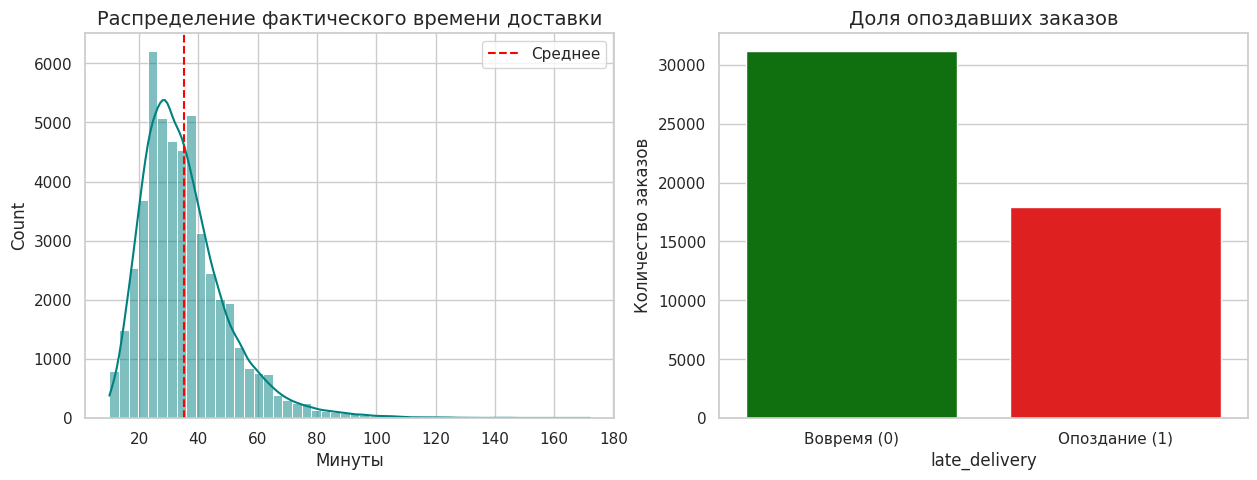

Среднее время доставки: 35.2 мин.
Медианное время: 33.0 мин.
Процент опозданий: 36.6%


In [110]:
fig, axes = plt.subplots(1, 2, figsize=(15,5))

#Гистограмма фактического времени
sns.histplot(df_main['actual_delivery_time_minutes'], bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Распределение фактического времени доставки', fontsize=14)
axes[0].set_xlabel('Минуты')
axes[0].axvline(df_main['actual_delivery_time_minutes'].mean(), color='red', linestyle='--', label='Среднее')
axes[0].legend()

#Баланс классов: опоздания
late_counts = df_main['late_delivery'].value_counts()
sns.barplot(x=late_counts.index, y=late_counts.values, ax=axes[1], palette=['green', 'red'])
axes[1].set_title('Доля опоздавших заказов', fontsize=14)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Вовремя (0)', 'Опоздание (1)'])
axes[1].set_ylabel('Количество заказов')
plt.show()
print(f"Среднее время доставки: {df_main['actual_delivery_time_minutes'].mean():.1f} мин.")
print(f"Медианное время: {df_main['actual_delivery_time_minutes'].median():.1f} мин.")
print(f"Процент опозданий: {df_main['late_delivery'].mean() * 100:.1f}%")

/tmp/ipykernel_2797/1370640542.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='weather', y='actual_delivery_time_minutes', data=df_main, ax=axes[0], palette='Pastel1')
/tmp/ipykernel_2797/1370640542.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='traffic_level', y='actual_delivery_time_minutes', data=df_main, ax=axes[1], palette='Pastel2')


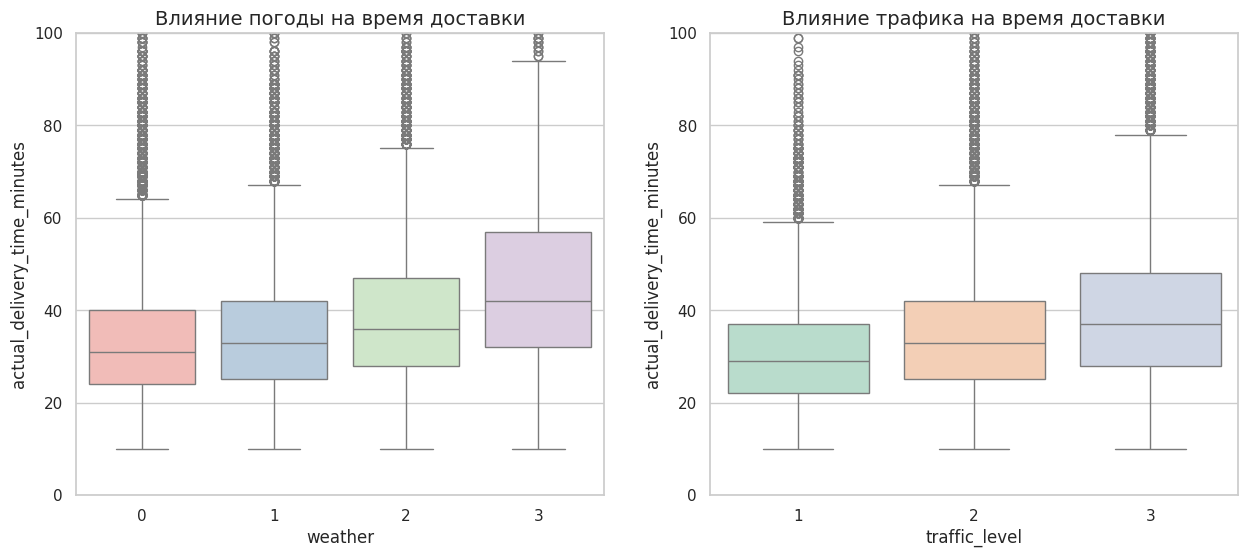


Процент опозданий в зависимости от погоды:


,late_delivery
weather,
3,89.187056
2,69.180019
1,38.764804
0,24.492946


In [111]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Влияние погоды
sns.boxplot(x='weather', y='actual_delivery_time_minutes', data=df_main, ax=axes[0], palette='Pastel1')
axes[0].set_title('Влияние погоды на время доставки', fontsize=14)
axes[0].set_ylim(0, 100) # Ограничим Y для читаемости выбросов

# Влияние трафика
sns.boxplot(x='traffic_level', y='actual_delivery_time_minutes', data=df_main, ax=axes[1], palette='Pastel2')
axes[1].set_title('Влияние трафика на время доставки', fontsize=14)
axes[1].set_ylim(0, 100)

plt.show()

# Посмотрим, как погода влияет именно на процент ОПАЗДАНИЙ (а не просто на время)
weather_late = df_main.groupby('weather')['late_delivery'].mean() * 100
print("\nПроцент опозданий в зависимости от погоды:")
display(weather_late.sort_values(ascending=False))

## Шаг 5: Визуализация корреляционной матрицы

Тепловая карта позволяет наглядно увидеть:
- Силу связи между таргетом и признаками
- Мультиколлинеарность (высокая корреляция между признаками)
- Паттерны, которые не видны в табличном выводе

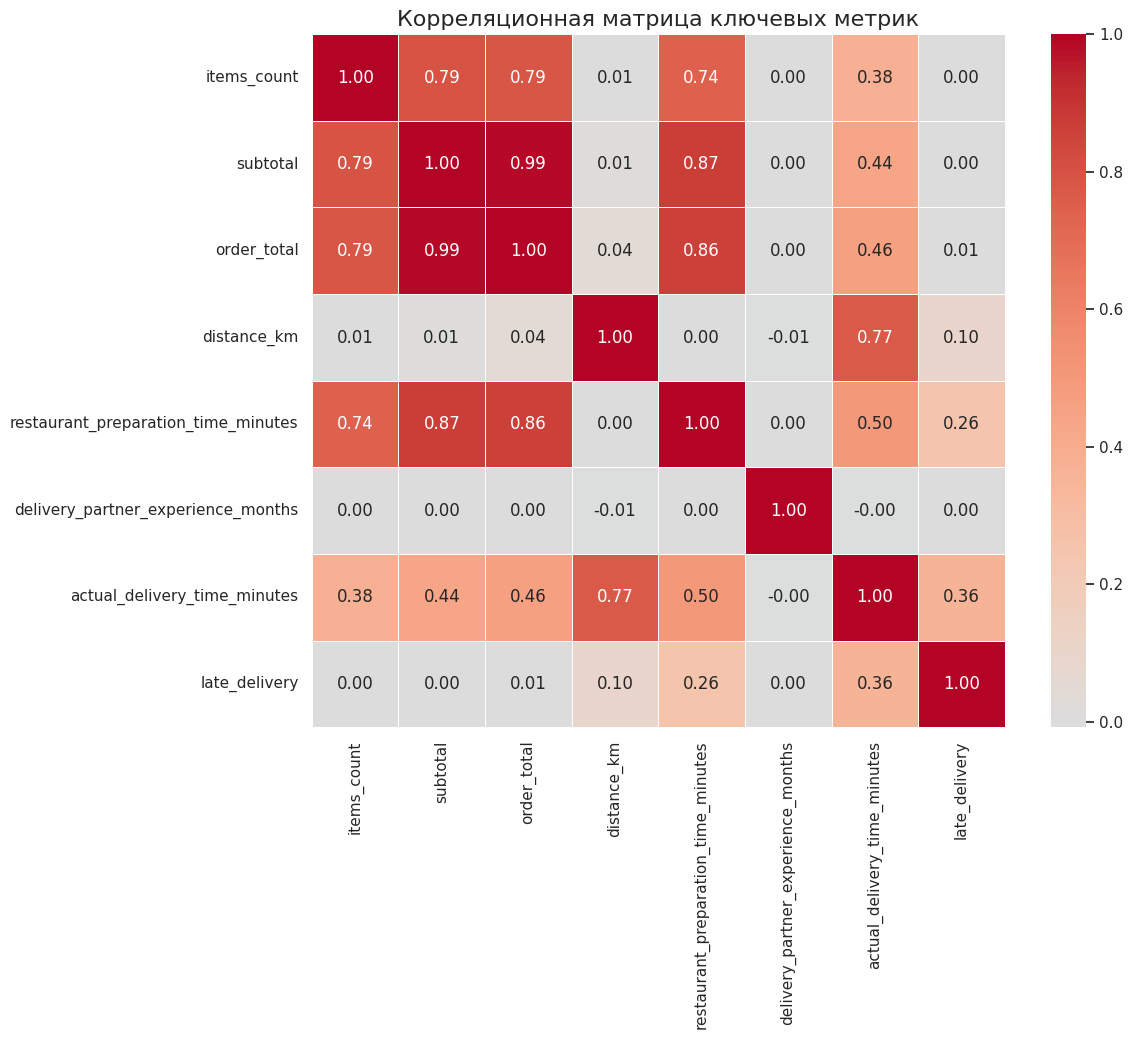

In [112]:
# Отберем числовые признаки, чтобы найти скрытые взаимосвязи
num_cols = ['items_count', 'subtotal', 'order_total', 'distance_km',
            'restaurant_preparation_time_minutes', 'delivery_partner_experience_months', 'actual_delivery_time_minutes', 'late_delivery']

corr_matrix = df_main[num_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Корреляционная матрица ключевых метрик', fontsize=16)
plt.show()

### Вывод по Шагу 5:
- На тепловой карте чётко виден **красный столбец** у `distance_km` — это сильная положительная связь с таргетом.
- Группа финансовых признаков (`order_total`, `subtotal`, `tax_amount`) имеет высокую корреляцию между собой (**мультиколлинеарность**). Для модели стоит оставить только один, например `order_total`.
- Признаки курьера почти не выделяются — их корреляция близка к нулю.

In [113]:
# Подготовка X и y
target = 'actual_delivery_time_minutes'

leak_cols = ['late_delivery', 'estimated_delivery_time_minutes', 'customer_rating']

feature_cols = [c for c in df_main.columns if c != target and c not in leak_cols]
X = df_main[feature_cols]
y = df_main[target]

print(f"Признаков: {len(feature_cols)}")
print(feature_cols)

Признаков: 20
['is_weekend', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'tip_amount', 'restaurant_preparation_time_minutes', 'distance_km', 'traffic_level', 'weather', 'delivery_partner_experience_months', 'delivery_partner_rating', 'is_dinner_rush', 'is_lunch_rush', 'is_night', 'day_of_week_num']


Вывод: estimated_delivery_time_minutes мы не используем как признак (это готовый ответ от старой системы), но ниже сравним с ним как с бизнес-baseline — честно и полезно.

In [114]:
# Разделение на train/test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape[0]}, Test: {X_test.shape[0]}")

Train: 39305, Test: 9827


In [115]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
results = []
def evaluate(name, y_true, y_pred):
  results.append({
      'Модель': name,
      'MAE (мин)': round(mean_absolute_error(y_true, y_pred), 2),
      'RMSE (мин)' : round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
      'R²': round(r2_score(y_true, y_pred), 3)
  })

dummy = DummyRegressor(strategy='median')
dummy.fit(X_train, y_train)
evaluate('Dummy (медиана)', y_test, dummy.predict(X_test))

Вывод: Dummy ничего не учит — это просто «типичная доставка». Ожидаемый MAE ≈ 11–12 мин (при std таргета ~14.7). Это наша точка отсчёта.

In [116]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate('Linear Regression', y_test, lr.predict(X_test))

# Интерпретация: сколько минут добавляет каждый признак
coef = pd.Series(lr.coef_, index=feature_cols).sort_values(key=abs, ascending=False)
print(coef.head(8))

traffic_level                          4.714677
distance_km                            4.029936
tax_amount                            -3.431165
weather                                3.141078
restaurant_preparation_time_minutes    1.006092
service_fee                           -0.428870
order_total                            0.419932
is_weekend                             0.380275
dtype: float64


Вывод: коэффициенты читаются напрямую: например, distance_km ≈ 3–4 значит «+1 км ≈ +3–4 минуты». Ожидаем MAE ≈ 4–6 мин и R² ≈ 0.8+ — линейная модель уже должна сильно побить Dummy.

In [117]:
# Старая система оценки времени — с ней должна конкурировать наша модель
eta_pred = df.loc[y_test.index, 'estimated_delivery_time_minutes']
evaluate('Текущая ETA (бизнес-baseline)', y_test, eta_pred)

pd.DataFrame(results)

,Модель,MAE (мин),RMSE (мин),R²
0,Dummy (медиана),10.94,15.02,-0.023
1,Linear Regression,2.83,3.91,0.931
2,Текущая ETA (бизнес-baseline),5.27,7.03,0.776


Вывод: это самый честный ориентир: если наша модель не лучше текущей ETA — бизнес-смысла в ней нет.